In [1]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
newsgroups = fetch_20newsgroups(
    subset='train',
    remove=('headers','footers','quotes')
)

documents = newsgroups.data

print("Number of documents:", len(documents))

Number of documents: 11314


In [3]:
vectorizer = CountVectorizer(
    stop_words='english',
    max_features=5000
)

X = vectorizer.fit_transform(documents)

print(X.shape)

(11314, 5000)


In [4]:
word_counts = np.array(X.sum(axis=0)).flatten()

print(word_counts[:20])

[1204  693  228  262  211  348   42  170  162   76   82   91  258   49
   70  103   49  505   44 1668]


In [5]:
theta_mle = word_counts / np.sum(word_counts)

print(theta_mle[:20])

[1.35897937e-03 7.82203240e-04 2.57348252e-04 2.95724746e-04
 2.38160005e-04 3.92794700e-04 4.74062569e-05 1.91882469e-04
 1.82852705e-04 8.57827507e-05 9.25550731e-05 1.02713557e-04
 2.91209864e-04 5.53072998e-05 7.90104282e-05 1.16258202e-04
 5.53072998e-05 5.70003804e-04 4.96636978e-05 1.88270563e-03]


In [6]:
alpha = 2

K = len(word_counts)

theta_map2 = (word_counts + alpha - 1) / (
    np.sum(word_counts) + K*(alpha-1)
)

print(theta_map2[:20])

[1.35247525e-03 7.78935956e-04 2.57026418e-04 2.95187545e-04
 2.37945854e-04 3.91712750e-04 4.82626024e-05 1.91928024e-04
 1.82948935e-04 8.64237299e-05 9.31580466e-05 1.03259521e-04
 2.90698001e-04 5.61193052e-05 7.96894133e-05 1.16728155e-04
 5.61193052e-05 5.67927368e-04 5.05073746e-05 1.87326241e-03]


In [7]:
alpha = 10

theta_map10 = (word_counts + alpha - 1) / (
    np.sum(word_counts) + K*(alpha-1)
)

print(theta_map10[:20])

[1.30295749e-03 7.54061135e-04 2.54576195e-04 2.91097675e-04
 2.36315455e-04 3.83475534e-04 5.47822192e-05 1.92274848e-04
 1.83681558e-04 9.13036987e-05 9.77486656e-05 1.07416116e-04
 2.86801030e-04 6.23013473e-05 8.48587317e-05 1.20306050e-04
 6.23013473e-05 5.52118837e-04 5.69305415e-05 1.80136827e-03]


In [8]:
alpha = 50

theta_map50 = (word_counts + alpha - 1) / (
    np.sum(word_counts) + K*(alpha-1)
)

print(theta_map50[:20])

[1.10790931e-03 6.56080371e-04 2.44924882e-04 2.74987864e-04
 2.29893391e-04 3.51029525e-04 8.04626870e-05 1.93640972e-04
 1.86567329e-04 1.10525669e-04 1.15830901e-04 1.23788749e-04
 2.71451043e-04 8.66521244e-05 1.05220437e-04 1.34399213e-04
 8.66521244e-05 4.89849765e-04 8.22310977e-05 1.51818059e-03]


In [9]:
vocab = vectorizer.get_feature_names_out()

for i in range(20):
    print(vocab[i])
    print("MLE :", theta_mle[i])
    print("MAP α=2 :", theta_map2[i])
    print("MAP α=10:", theta_map10[i])
    print("MAP α=50:", theta_map50[i])
    print()

00
MLE : 0.0013589793658623029
MAP α=2 : 0.0013524752541923927
MAP α=10: 0.001302957487923743
MAP α=50: 0.0011079093052886976

000
MLE : 0.0007822032396533023
MAP α=2 : 0.000778935955526573
MAP α=10: 0.0007540611348082998
MAP α=50: 0.0006560803707296197

01
MLE : 0.00025734825200714705
MAP α=2 : 0.0002570264176017078
MAP α=10: 0.00025457619508485334
MAP α=50: 0.00024492488233437287

02
MLE : 0.0002957247457275111
MAP α=2 : 0.0002951875451058915
MAP α=10: 0.0002910976745485032
MAP α=50: 0.0002749878642815522

03
MLE : 0.00023816000514696503
MAP α=2 : 0.00023794585384961597
MAP α=10: 0.00023631545535302844
MAP α=50: 0.0002298933913607832

04
MLE : 0.0003927947004319613
MAP α=2 : 0.000391712749969415
MAP α=10: 0.0003834755343683234
MAP α=50: 0.0003510295245008882

040
MLE : 4.7406256948684985e-05
MAP α=2 : 4.826260243176173e-05
MAP α=10: 5.478221919547477e-05
MAP α=50: 8.046268697627411e-05

05
MLE : 0.00019188246860182018
MAP α=2 : 0.0001919280236239827
MAP α=10: 0.0001922748477645095
MA

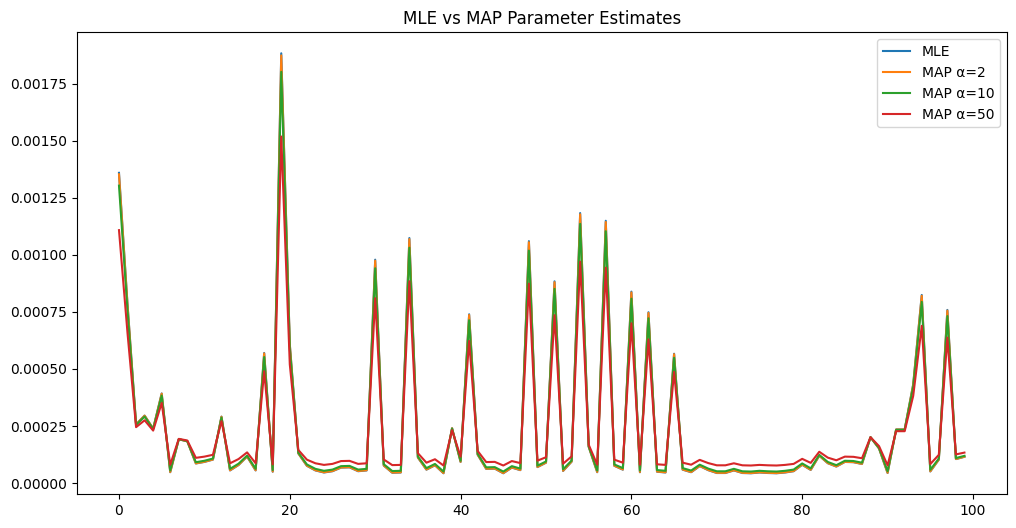

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(theta_mle[:100], label="MLE")
plt.plot(theta_map2[:100], label="MAP α=2")
plt.plot(theta_map10[:100], label="MAP α=10")
plt.plot(theta_map50[:100], label="MAP α=50")

plt.legend()
plt.title("MLE vs MAP Parameter Estimates")
plt.show()